# Circuit Parameter Fitting: The Single Microwave Photon Detector (SMPD)

This tutorial introduces **QBrAn's parameter fitting module** (`circuit.fit_parameters`) and demonstrates how to simulate a **Single Microwave Photon Detector (SMPD)** operating via 4-wave mixing parametric conversion, based on **L. Pallegoix et al. (Phys. Rev. Applied 25, 044064, 2026)**.

---

## 1. Bare-to-Dressed Parameter

Usually, experimental measurements yield dressed observables:
* Dressed transition frequencies: $\tilde{\omega}_i$
* Dressed transmon self-Kerr (anharmonicity): $\tilde{\alpha} = \tilde{\omega}_{12} - \tilde{\omega}_{01}$
* Dispersive cross-Kerr shifts between modes $i$ and $j$: $\chi_{ij} = E(1_i, 1_j) - E(1_i, 0_j) - E(0_i, 1_j) + E(0_i, 0_j)$

However, numerical solvers require bare parameters. Standard perturbative formulas (e.g., $\chi \approx 2 g^2 \alpha / [\Delta (\Delta - \alpha)]$) are only approximate and fail for moderate coupling strengths or low detunings.

### QBrAn's Numerical Fitting (`circuit.fit_parameters`)
QBrAn solves the inverse eigenvalue problem numerically:
1. **Uninitialized Definition**: Components and interactions are declared without specifying bare energies upfront.
2. **Target Matching**: The user specifies target dressed frequencies and dispersive shifts.
3. **Exact Diagonalization Inversion**: A non-linear numerical optimizer iteratively diagonalizes the full multi-mode circuit Hamiltonian, adjusting bare parameters until dressed eigenenergies match the experimental targets.
4. **In-Place Update**: The converged bare parameters are written directly to the circuit components and interactions.

In [155]:
import qbran as br

import numpy as np
import matplotlib.pyplot as plt

# Circuit definition
tmon   = br.Transmon(name="tmon", truncated_dim=13)
buffer = br.Resonator(name="buffer", truncated_dim=3)
waste  = br.Resonator(name="waste", truncated_dim=3)

circuit = br.HilbertSpace([tmon, buffer, waste])
circuit.add_interaction(tmon, buffer)
circuit.add_interaction(tmon, waste)

# Parameter from L. Pallegoix et al. Phys. Rev. A 25, 044064 (2026)
fit = circuit.fit_parameters(
    target_frequencies = {
        "tmon":  (6.533, 240e-3),
        "waste":  8.475,
        "buffer": 7.706,
    },
    target_dispersive_shifts = {
        ("tmon", "buffer"): 3.5e-3,
        ("tmon", "waste"):  16e-3,
    }
)
print(fit.summary())

QBRAN Circuit Parameter Fit Results
Status: SUCCESS (`gtol` termination condition is satisfied.)
Iterations: 8 | Max Residual: 0.0000 MHz (0.00 kHz)
Observable                 Target (GHz)     Fitted (GHz)     Residual (kHz)   Fitted Bare Parameter
------------------------------------------------------------------------------------------------------------------------
tmon.frequency             6.533000         6.533000         +0.000           tmon.EJ            =   24.500931 GHz
waste.frequency            8.475000         8.475000         +0.000           waste.E_osc        =    8.421213 GHz
buffer.frequency           7.706000         7.706000         +0.000           buffer.E_osc       =    7.697607 GHz
tmon.anharmonicity         -0.240000        -0.240000        -0.000           tmon.EC            =    0.240161 GHz
chi_tmon_buffer            -0.003500        -0.003500        -0.000           g_tmon_buffer      =    0.081203 GHz
chi_tmon_waste             -0.016000        -0.016000  

## 2. 4-Wave Mixing Parametric Conversion

To detect an itinerant photon entering the buffer resonator, a microwave pump tone at frequency $\omega_p$ is applied to the transmon. The four-wave mixing process mediated by the transmon nonlinearity satisfies the parametric resonance condition: $\omega_p + \omega_{\text{buffer}} \approx \omega_{\text{tmon}} + \omega_{\text{waste}}$.

This pump tone coherently drives the conversion: $|0_t, 1_b, 0_w\rangle \longleftrightarrow |1_t, 0_b, 1_w\rangle$.

Below, we track three product states:
* $|0_t, 0_b, 0_w\rangle$: Ground state
* $|0_t, 1_b, 0_w\rangle$: Single photon in the buffer mode
* $|1_t, 0_b, 1_w\rangle$: Parametrically converted state (transmon excited + waste photon)

In [156]:
tracked = [
    circuit.state_to_index(0, 0, 0),
    circuit.state_to_index(0, 1, 0),
    circuit.state_to_index(1, 0, 1),
]

ops = br.Options(tracked_states=tracked, backend="numpy", n_workers=28)
amp_p  = np.linspace(0, 0.75, 200)
freq_p = np.linspace(7.2, 7.3, 200)

analysis = circuit.BranchAnalysis(kind="propagator", options=ops)
results = analysis.run(drive_freq=freq_p, drive_amp=amp_p)

Branch Analysis (28 workers): 100%|██████████| 200/200 [01:14<00:00,  2.68it/s]


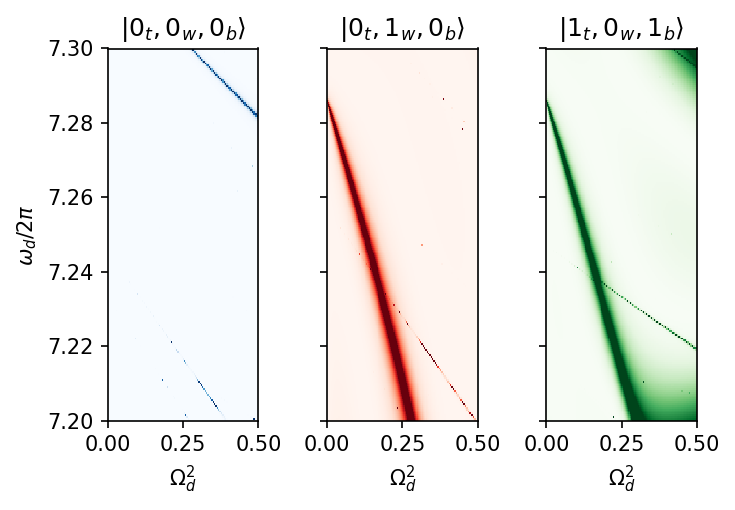

In [158]:
cmaps = ["Blues", "Reds", "Greens"]
titles = [r"$|0_t,0_w,0_b\rangle$", r"$|0_t,1_w,0_b\rangle$", r"$|1_t,0_w,1_b\rangle$"]

fig, axs = plt.subplots(1, 3, figsize=(5, 3.5), dpi=150, sharey=True)
for i, ax in enumerate(axs):
    ax.pcolormesh(amp_p**2, freq_p, results.hybridization[:, :, i], cmap=cmaps[i], vmin=0, vmax=0.3)
    ax.set_title(titles[i])
    ax.set_xlabel(r"$\Omega_d^2$")
    ax.set_xlim(0, 0.5)
    ax.set_ylim(7.2, 7.3)
axs[0].set_ylabel(r"$\omega_d/2\pi$")
fig.tight_layout()
plt.show()

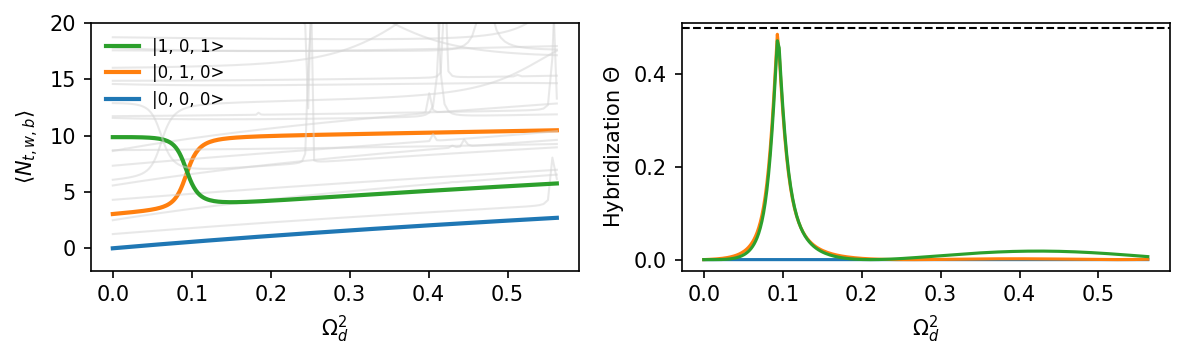

In [182]:
omega_probe = 7.26
idx = np.argmin(np.abs(freq_p - omega_probe))

avg_excitation = results.avg_excitation[idx, :, :]
hybridization = results.hybridization[idx, :, :]

colored = tracked

fig, axs = plt.subplots(1, 2, figsize=(8, 2.5), dpi=150)

for i in range(avg_excitation.shape[1]):
    col = f'C{colored.index(i)}' if i in colored else 'lightgray'
    legend = circuit.state_label(i) if i in colored else None
    alp = 1.0 if i in colored else 0.5
    lw  = 2.0 if i in colored else 1.0
    axs[0].plot(amp_p**2, avg_excitation[:, i], color=col, alpha=alp, linewidth=lw, label=legend)
axs[0].set_ylim(-2, 20)
axs[0].legend(loc='upper left', fontsize=8, frameon=False, reverse=True)

for i, _ in enumerate(colored):
    axs[1].plot(amp_p**2, hybridization[:, i])
axs[1].axhline(0.5, color='k', ls='--', lw=1)
for i in [0,1]: axs[i].set_xlabel(r'$\Omega_d^2$')
axs[0].set_ylabel(r'$\langle N_{t,w,b} \rangle$')
axs[1].set_ylabel(r'Hybridization $\Theta$')

fig.tight_layout()
plt.show()

## 5. References

1. **Single Microwave Photon Detection (SMPD)**:
   * L. Pallegoix, et al., *"Enhancing the sensitivity of single microwave photon detection with bandwidth tunability"*, [Phys. Rev. Applied **25**, 044064 (2026)](https://doi.org/10.1103/dbqj-qld5) (arXiv:2501.07354).
   * R. Lescanne, et al., *"Irreversible qubit-photon coupling for the detection of itinerant microwave photons"*, [Phys. Rev. X **10**, 021038 (2020)](https://doi.org/10.1103/PhysRevX.10.021038).